Superstore Analysis — Modular Version

An end-to-end data analysis using modular Python modules.

In [2]:
import sys
import os
import pandas as pd
src_path = r'C:\Users\MehrIT\Desktop\ds_practice\SampleSuperstore\src'
if src_path not in sys.path:
    sys.path.append(src_path)
import matplotlib.pyplot as plt
import seaborn as sns
import data_loader as dl
import visualization as viz

from data_loader import load_data
from data_cleaning import clean_data
from feature_engineering import add_time_features
from eda import (
    get_monthly_summary,
    get_category_summary,
    get_region_summary,
    get_segment_summary,
    get_peak_months,
)
from visualization import (
    plot_monthly_trend,
    plot_category_performance,
    plot_regional_performance,
    plot_discount_vs_profit,
    plot_segment_share,
    plot_dashboard,
)

%matplotlib inline
sns.set_style("whitegrid")

Data loading

In [ ]:
df=dl.load_data('../data/Sample-Superstore.xlsx')
df = load_data(r'C:\Users\MehrIT\Desktop\ds_practice\SampleSuperstore\SampleSuperstore\data\Sample-Superstore.xlsx')
df.head()
print(df.shape)
print(df.columns.tolist())

✅ Data loaded: 9994 rows × 21 columns
✅ Data loaded: 9994 rows × 21 columns
(9994, 21)
['Unnamed: 0', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


Data cleaning

In [ ]:
df=clean_data(df)
df.head()

DATA CLEANING
✓ Removed duplicates: 8 rows
✓ Converted 4 columns to category
✓ Removed invalid values: 64 rows

✅ Final shape: 9922 rows × 21 columns


,Unnamed: 0,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Exploratory Data Analysis

In [ ]:
df=add_time_features(df)
df.head()
print(df.columns.tolist())

✅ Added time features: Year, Month, Month_Year, Quarter, Shipping Days
['Unnamed: 0', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Month_Year', 'Quarter', 'Shipping Days']


In [ ]:
monthly = get_monthly_summary(df)
cat = get_category_summary(df)
region = get_region_summary(df)
segment = get_segment_summary(df)
peaks = get_peak_months(df)

print("All summaries computed!")

All summaries computed!


visualizations

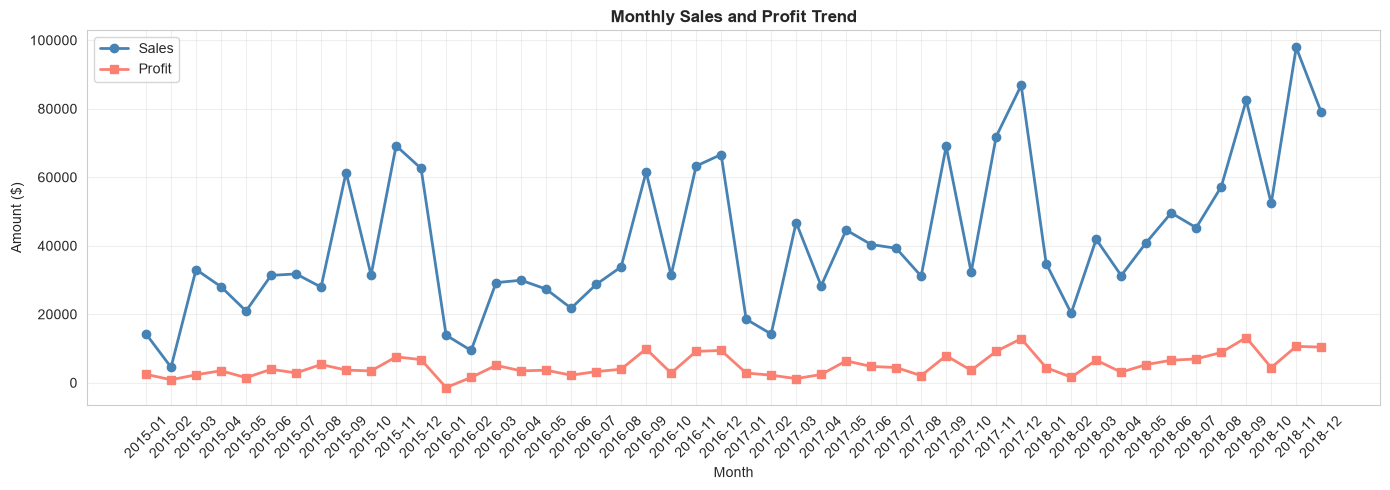

In [ ]:
plot_monthly_trend(monthly, '../images/monthly_trend.png')

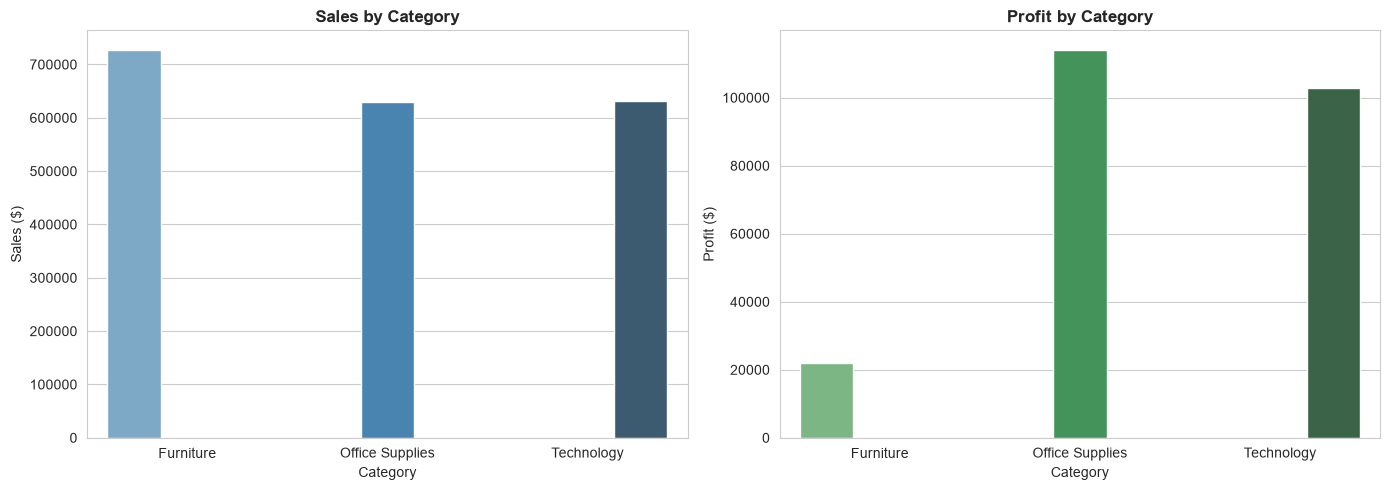

In [ ]:
plot_category_performance(cat, '../images/category.png')

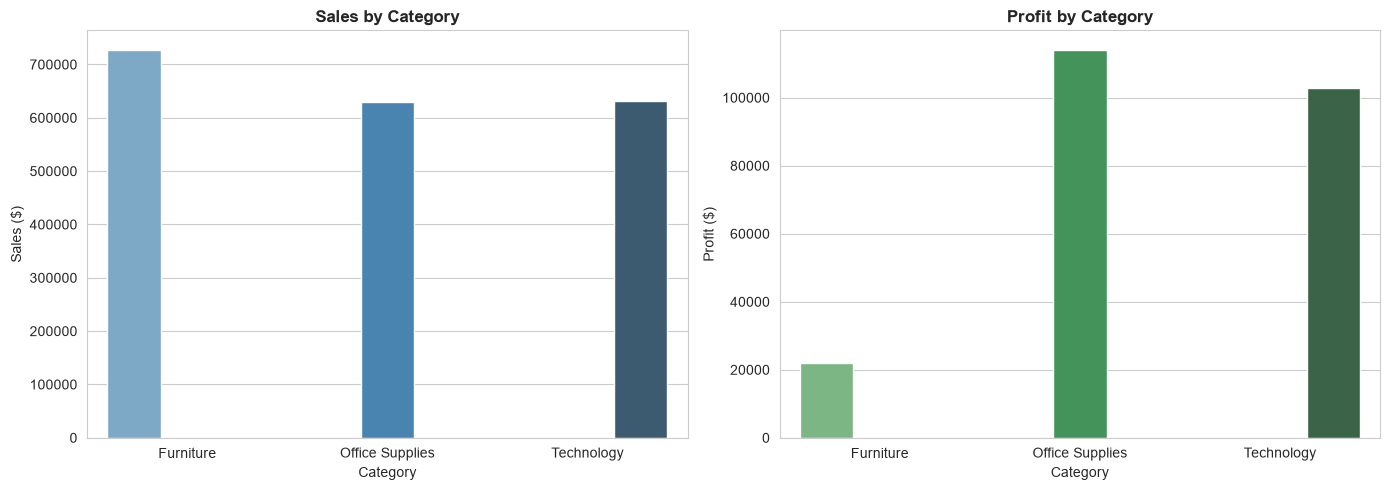

In [ ]:
plot_category_performance(cat, '../images/category.png')

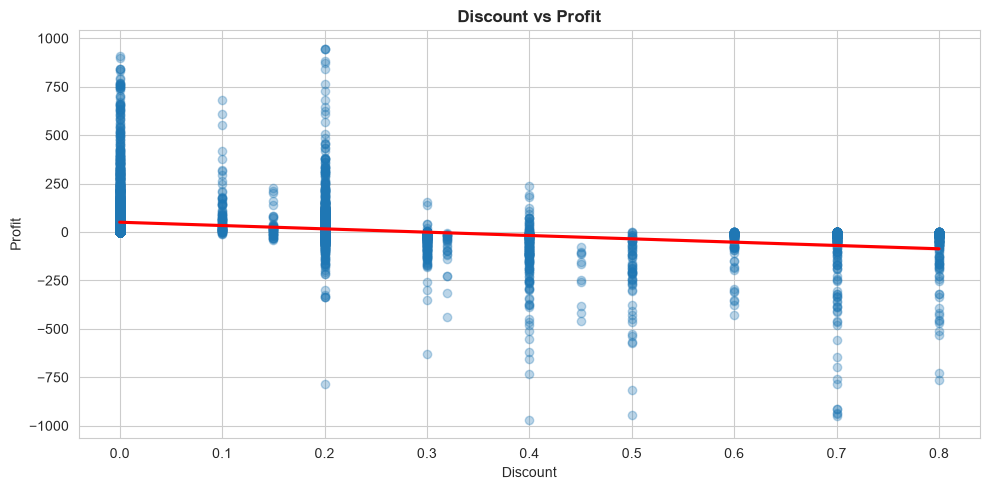

In [ ]:
plot_discount_vs_profit(df, '../images/discount.png')

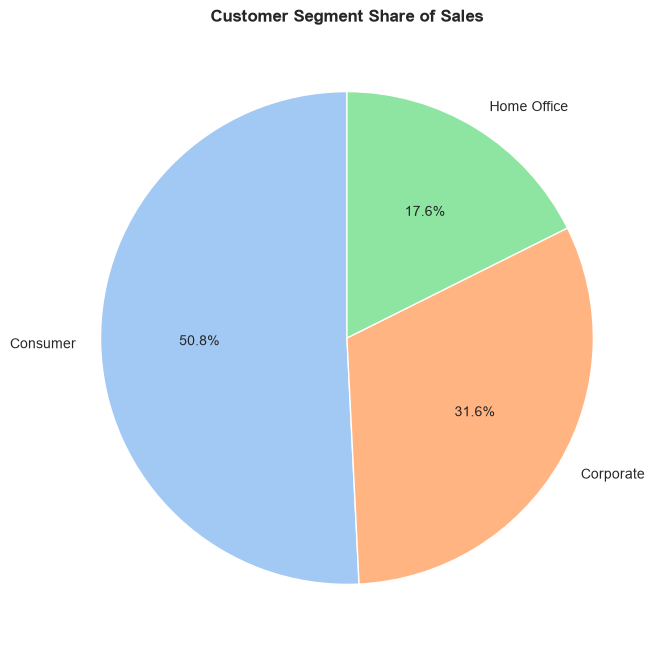

In [ ]:
plot_segment_share(segment, '../images/segment.png')

## 6. Consolidated Dashboard

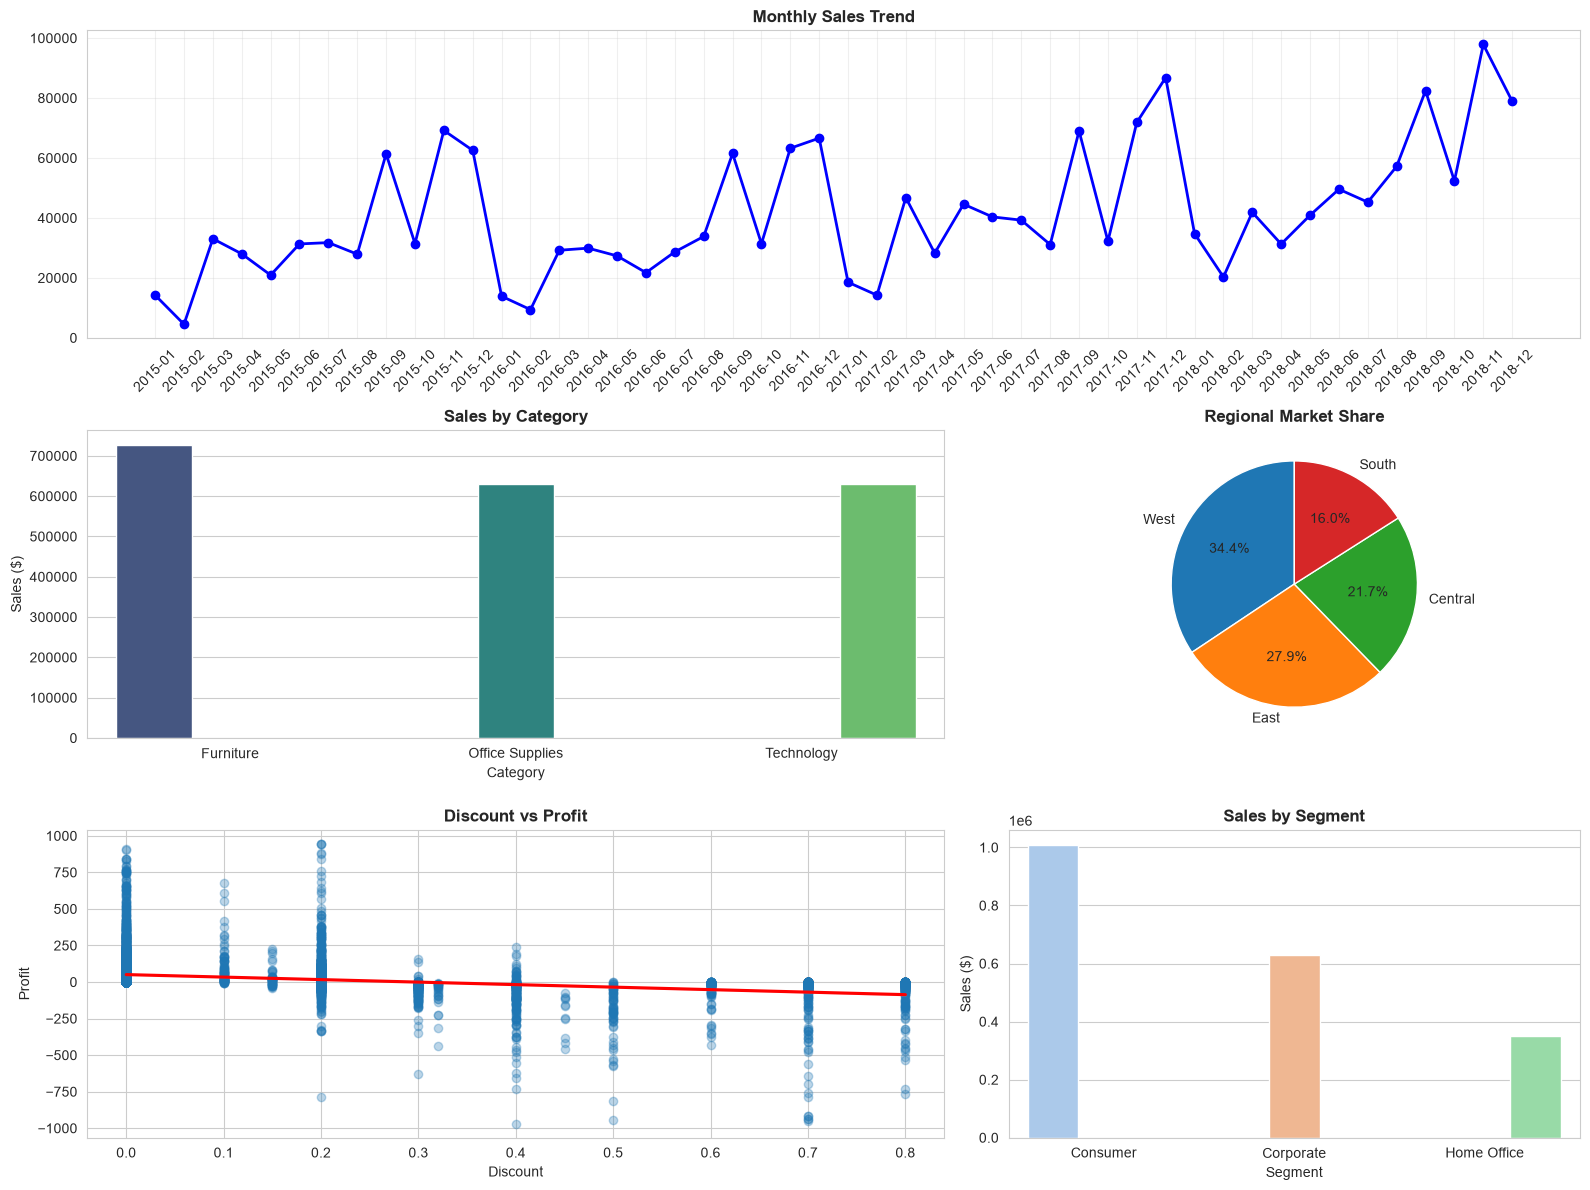

In [ ]:
plot_dashboard(monthly, cat, region, df, segment, '../images/dashboard.png')

## 7. Key Findings

In [ ]:

print(peaks['peak_sales'].to_string(index=False))
print(f"\nTop 3 Profit Months:")
print(peaks['peak_profit'].to_string(index=False))
print(f"\nRegional Performance:")
print(region.to_string(index=False))

Month_Year  total_sales
   2018-11    97878.307
   2017-12    86819.923
   2018-09    82440.322

Top 3 Profit Months:
Month_Year  total_profit
   2018-09    13184.7872
   2017-12    12855.8891
   2018-11    10620.0203

Regional Performance:
 Region  total_sales  total_profit  profit_margin_%  sales_share_%
   West  683529.4475    95553.6161            13.98          34.37
   East  554990.7990    64197.9752            11.57          27.90
Central  432515.0728    32092.6419             7.42          21.75
  South  317934.5420    46871.9911            14.74          15.98


In [3]:
!jupyter nbconvert --to html analysis_modular.ipynb

[NbConvertApp] Converting notebook analysis_modular.ipynb to html
C:\Users\MehrIT\AppData\Local\Programs\Python\Python313\share\jupyter\nbconvert\templates\base\display_priority.j2:32: UserWarning: Your element with mimetype(s) dict_keys(['application/vnd.plotly.v1+json']) is not able to be represented.
  {%- elif type == 'text/vnd.mermaid' -%}
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 847109 bytes to analysis_modular.html


In [ ]:
# ۱. ساخت و ذخیره نمودار میله‌ای
fig_bar = viz.plot_bar(df, x='Category', y='Sales', color='Region', title='مقایسه فروش')
fig_bar.show()
viz.save_interactive_html(fig_bar, "superstore_bar_chart")

# ۲. ساخت و ذخیره نمودار پراکندگی
fig_scatter = viz.plot_scatter(df, x='Sales', y='Profit', color='Category', title='رابطه سود و فروش')
fig_scatter.show()
viz.save_interactive_html(fig_scatter, "superstore_scatter_plot")

# ۳. ساخت و ذخیره نمودار هیستوگرام
fig_hist = viz.plot_histogram(df, x='Profit', y='Profit', color='Category', title='توزیع سود')
fig_hist.show()
viz.save_interactive_html(fig_hist, "superstore_profit_histogram")